# Kmeans
- K-means clusterning is an unsupervised learning algorithem. there is no labeled data for this clustering unlike in supervised learning.K-means perform the division of the object in cluster that share similarities and disimiler to the object belonging to another cluster. the term 'k' is a number of groups or cluster. the goal of clustering is to divide the population or set of data points into a number of groups or cluster so that the data points within each groups are more comparable to one another and diffent from the data point within another group. it is esentially a grouping of things based on how similaer and differnt they are to one another.

In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [38]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [39]:
df = pd.read_csv('income/income.csv')
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


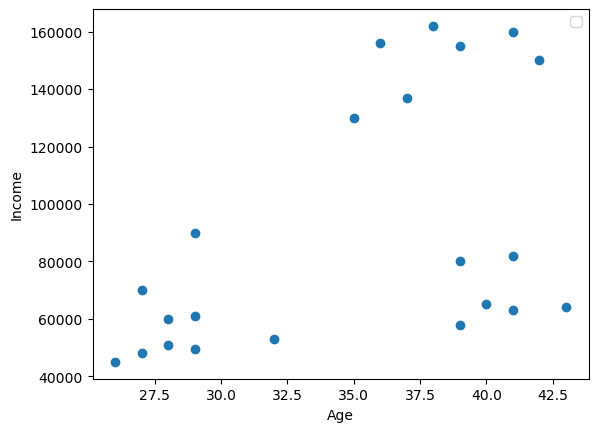

In [40]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income')
plt.legend()

In [41]:
km = KMeans(n_clusters=3)
y_pred=km.fit_predict(df[['Age','Income($)']])
y_pred

array([1, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2],
      dtype=int32)

In [42]:
#sns.scatterplot(x=df['Age'],y=df['Income($)'],hue=df['cluster'])
df['cluster']=y_pred

In [43]:
km.cluster_centers_

array([[3.82857143e+01, 1.50000000e+05],
       [3.40000000e+01, 8.05000000e+04],
       [3.29090909e+01, 5.61363636e+04]])

Text(0, 0.5, 'Income')

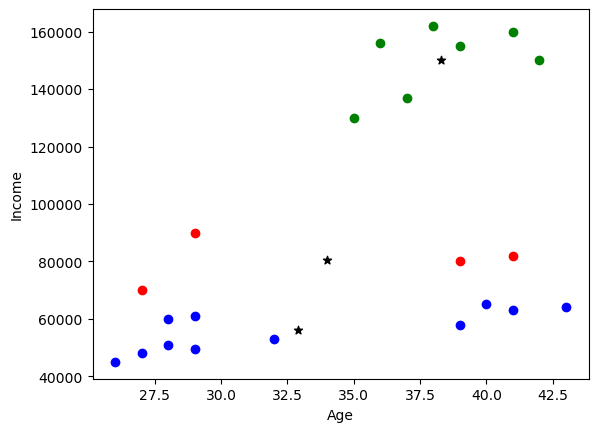

In [44]:
df1 = df[df.cluster == 0]
df2 = df[df.cluster == 1]
df3 = df[df.cluster == 2]

plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='blue')

plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='black',marker="*",label='Centroid')
plt.xlabel('Age')
plt.ylabel('Income')


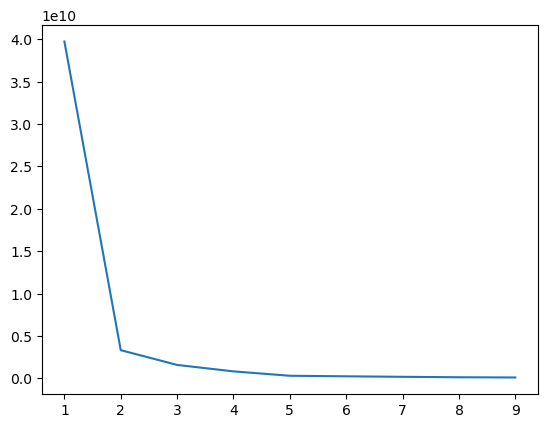

In [47]:
sse=[]
kk=[]

for k in range(1,10):
    km=KMeans(n_clusters=k)
    km.fit(df[['Age','Income($)']])
    sse.append(km.inertia_)
    kk.append(k)
plt.plot(kk,sse)

In [48]:
from sklearn.preprocessing import MinMaxScaler    

In [49]:
scaler = MinMaxScaler()

In [50]:
scaler.fit(df[['Income($)']])

MinMaxScaler()

In [51]:
df['income']=scaler.fit_transform(df[['Income($)']])

In [52]:
scaler.fit(df[['Age']])
df['Age']=scaler.fit_transform(df[['Age']])
df

,Name,Age,Income($),cluster,income
0,Rob,0.058824,70000,1,0.213675
1,Michael,0.176471,90000,1,0.384615
2,Mohan,0.176471,61000,2,0.136752
3,Ismail,0.117647,60000,2,0.128205
4,Kory,0.941176,150000,0,0.897436
5,Gautam,0.764706,155000,0,0.940171
6,David,0.882353,160000,0,0.982906
7,Andrea,0.705882,162000,0,1.000000
8,Brad,0.588235,156000,0,0.948718
9,Angelina,0.529412,130000,0,0.726496


In [53]:
y_pred=km.fit_predict(df[['Age','income']])
y_pred

array([5, 8, 5, 5, 0, 7, 0, 7, 7, 4, 4, 3, 3, 3, 3, 1, 6, 6, 6, 2, 2, 6],
      dtype=int32)

In [54]:
df['clusters'] = y_pred
df

,Name,Age,Income($),cluster,income,clusters
0,Rob,0.058824,70000,1,0.213675,5
1,Michael,0.176471,90000,1,0.384615,8
2,Mohan,0.176471,61000,2,0.136752,5
3,Ismail,0.117647,60000,2,0.128205,5
4,Kory,0.941176,150000,0,0.897436,0
5,Gautam,0.764706,155000,0,0.940171,7
6,David,0.882353,160000,0,0.982906,0
7,Andrea,0.705882,162000,0,1.000000,7
8,Brad,0.588235,156000,0,0.948718,7
9,Angelina,0.529412,130000,0,0.726496,4


Text(0, 0.5, 'Income')

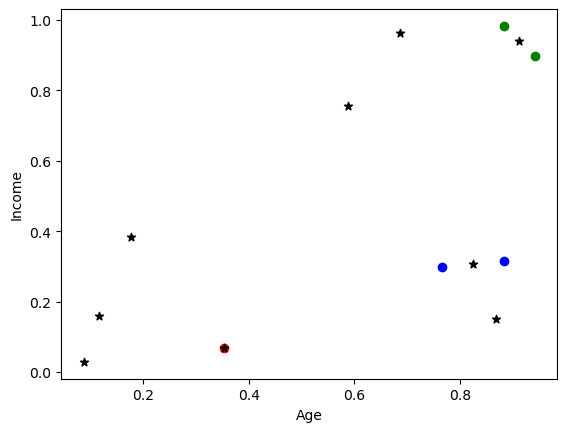

In [55]:
df1 = df[df.clusters == 0]
df2 = df[df.clusters == 1]
df3 = df[df.clusters == 2]

plt.scatter(df1.Age,df1['income'],color='green')
plt.scatter(df2.Age,df2['income'],color='red')
plt.scatter(df3.Age,df3['income'],color='blue')

plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='black',marker="*",label='Centroid')
plt.xlabel('Age')
plt.ylabel('Income')


In [56]:
# within cluster set sum of squared error
#sum of squared error (SSE)

sse=[]
kk=[]

for k in range(1,10):
    km=KMeans(n_clusters=k)
    km.fit(df[['Age','income']])
    sse.append(km.inertia_)
    kk.append(k)
    

In [57]:
sse

[5.434011511988178,
 2.091136388699078,
 0.4750783498553096,
 0.3491047094419566,
 0.2621792762345213,
 0.21055478995472496,
 0.16869711728567788,
 0.13265419827245162,
 0.10497488680620906]

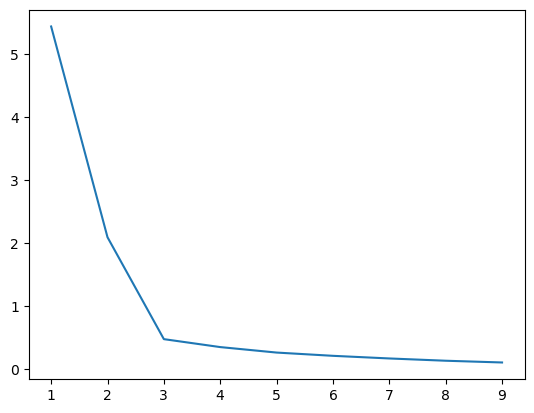

In [58]:
plt.plot(kk,sse)